# Travel-Time Intelligence Notebook (ESRI + OpenStreetMap + EarthMapper)

This notebook builds a **50-minute travel-time area** from a center location (example: Madrid), then combines:

1. **ESRI GeocodeServer** for location candidate intelligence
2. **OpenStreetMap-based isochrone** (OpenRouteService, OSM data)
3. **EarthMapper API** for earth features inside that travel-time area (lakes, rivers, roads, regions, places, etc.)

It keeps the same robustness principle used in your comparison notebook: **client-side geometry filtering** against the requested area.

In [1]:
import os
from typing import Any

import requests
import pandas as pd
import geopandas as gpd

from shapely import wkt
from shapely.geometry import Point, Polygon, MultiPolygon, LineString, MultiLineString, shape

from dotenv import load_dotenv

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_colwidth", 200)

In [2]:
# Configuration
load_dotenv()

EARTHMAPPER_API_BASE = os.getenv("EARTHMAPPER_API_BASE", "http://127.0.0.1:8000")
EARTHMAPPER_FEATURES_URL = f"{EARTHMAPPER_API_BASE.rstrip('/')}/features"

ESRI_GEOCODE_URL = os.getenv(
    "ESRI_GEOCODE_URL",
    "https://geocode-api.arcgis.com/arcgis/rest/services/World/GeocodeServer/findAddressCandidates",
)
ESRI_API_KEY = os.getenv("ESRI_API_KEY")

# OpenRouteService uses OSM data for isochrones.
# Add your key in .env as OSM_ORS_API_KEY when available.
OSM_ORS_API_KEY = os.getenv("OSM_ORS_API_KEY")
OSM_ORS_ISOCHRONE_URL = os.getenv("OSM_ORS_ISOCHRONE_URL", "https://api.openrouteservice.org/v2/isochrones")

CATEGORIES = ["administrative", "hydrography", "transport", "places"]

print("EarthMapper endpoint:", EARTHMAPPER_FEATURES_URL)
print("ESRI endpoint:", ESRI_GEOCODE_URL)
print("ESRI key loaded:", bool(ESRI_API_KEY))
print("OpenRouteService key loaded:", bool(OSM_ORS_API_KEY))

EarthMapper endpoint: http://127.0.0.1:8000/features
ESRI endpoint: https://geocode-api.arcgis.com/arcgis/rest/services/World/GeocodeServer/findAddressCandidates
ESRI key loaded: True
OpenRouteService key loaded: True


In [3]:
# Core helpers
def esri_auth_params() -> dict[str, Any]:
    return {"token": ESRI_API_KEY} if ESRI_API_KEY else {}


def parse_earthmapper_geometry(rec: dict[str, Any]):
    if isinstance(rec.get("geometry"), dict):
        try:
            return shape(rec["geometry"])
        except Exception:
            pass

    geom_val = rec.get("geom")
    centroid_val = rec.get("centroid")

    if isinstance(geom_val, dict):
        try:
            return shape(geom_val)
        except Exception:
            pass
    if isinstance(geom_val, str):
        try:
            return wkt.loads(geom_val)
        except Exception:
            pass

    if isinstance(centroid_val, dict):
        try:
            return shape(centroid_val)
        except Exception:
            pass
    if isinstance(centroid_val, str):
        try:
            return wkt.loads(centroid_val)
        except Exception:
            pass

    coords = rec.get("coords")
    if isinstance(coords, dict) and coords.get("x") is not None and coords.get("y") is not None:
        return Point(float(coords["x"]), float(coords["y"]))

    return None


def geometry_intersects_area(geom, area_geom) -> bool:
    if geom is None or area_geom is None:
        return False
    if geom.is_empty or area_geom.is_empty:
        return False
    return geom.intersects(area_geom)


def polygon_to_bbox(poly) -> list[float]:
    minx, miny, maxx, maxy = poly.bounds
    return [float(minx), float(miny), float(maxx), float(maxy)]

In [4]:
# ESRI center geocoding + OpenStreetMap isochrone
def geocode_center_point(address: str, country_hint: str = "ESP") -> dict[str, Any] | None:
    params = {
        "f": "json",
        "singleLine": address,
        "countryCode": country_hint,
        "maxLocations": 1,
        "outFields": "*",
        **esri_auth_params(),
    }
    resp = requests.get(ESRI_GEOCODE_URL, params=params, timeout=30)
    resp.raise_for_status()
    payload = resp.json()
    cands = payload.get("candidates", [])
    if not cands:
        return None
    best = cands[0]
    loc = best.get("location") or {}
    if "x" not in loc or "y" not in loc:
        return None
    return {
        "name": best.get("address"),
        "point": Point(float(loc["x"]), float(loc["y"])),
        "raw": best,
    }


def fallback_time_circle(center_point: Point, minutes: int, speed_kmh: float = 35.0):
    # Approximation used only when OSM isochrone key is unavailable.
    km = speed_kmh * (minutes / 60.0)
    deg = km / 111.32
    return center_point.buffer(deg)


def fetch_osm_isochrone(center_point: Point, minutes: int = 50, profile: str = "driving-car"):
    if not OSM_ORS_API_KEY:
        print("OSM_ORS_API_KEY not found. Using fallback radius approximation.")
        return fallback_time_circle(center_point, minutes=minutes, speed_kmh=35.0), "fallback_circle"

    headers = {"Authorization": OSM_ORS_API_KEY, "Content-Type": "application/json"}
    body = {
        "locations": [[float(center_point.x), float(center_point.y)]],
        "range": [int(minutes) * 60],
        "range_type": "time",
    }

    url = f"{OSM_ORS_ISOCHRONE_URL.rstrip('/')}/{profile}"
    resp = requests.post(url, headers=headers, json=body, timeout=45)
    resp.raise_for_status()
    payload = resp.json()

    feats = payload.get("features", []) if isinstance(payload, dict) else []
    if not feats:
        raise ValueError("No isochrone features returned from OSM service")

    iso = shape(feats[0]["geometry"])
    return iso, "osm_ors_isochrone"

In [5]:
# EarthMapper + ESRI data collection inside travel-time area
def normalize_earthmapper_features(items: list[dict[str, Any]], category: str) -> pd.DataFrame:
    rows = []
    for r in items:
        props = r.get("properties") if isinstance(r.get("properties"), dict) else {}
        geom = parse_earthmapper_geometry(r)
        rows.append({
            "id": str(r.get("id")) if r.get("id") is not None else None,
            "name": r.get("name") or props.get("name") or props.get("NAME") or props.get("Name"),
            "category": r.get("category") or category,
            "subcategory": r.get("subcategory") or props.get("subcategory"),
            "geometry": geom,
            "properties": props if props else r,
            "source": "earthmapper",
        })
    return pd.DataFrame(rows)


def fetch_earthmapper_in_area(area_poly, category: str, limit: int = 500) -> pd.DataFrame:
    bbox = polygon_to_bbox(area_poly)
    params = {
        "bbox": ",".join(str(v) for v in bbox),
        "category": category,
        "limit": int(limit),
    }
    resp = requests.get(EARTHMAPPER_FEATURES_URL, params=params, timeout=60)
    resp.raise_for_status()
    data = resp.json()
    items = data if isinstance(data, list) else data.get("features", data.get("results", []))

    # Client-side clipping validation to avoid out-of-area rows.
    filtered = []
    for item in items:
        geom = parse_earthmapper_geometry(item)
        if geometry_intersects_area(geom, area_poly):
            filtered.append(item)

    df = normalize_earthmapper_features(filtered, category=category)
    if not df.empty:
        df["centroid"] = df["geometry"].apply(lambda g: g.centroid if g is not None and not g.is_empty else None)
    return df


ESRI_SEED_TERMS = {
    "administrative": ["city hall", "municipality", "province"],
    "hydrography": ["river", "lake", "reservoir"],
    "transport": ["airport", "train station", "bus station", "highway"],
    "places": ["hospital", "school", "museum", "park"],
}


def fetch_esri_in_area(area_poly, category: str, max_per_seed: int = 3) -> pd.DataFrame:
    min_lon, min_lat, max_lon, max_lat = area_poly.bounds
    center_lon = (min_lon + max_lon) / 2.0
    center_lat = (min_lat + max_lat) / 2.0

    rows = []
    seen = set()

    for seed in ESRI_SEED_TERMS.get(category, [category]):
        params = {
            "f": "json",
            "singleLine": seed,
            "location": f"{center_lon},{center_lat}"
            ,"searchExtent": f"{min_lon},{min_lat},{max_lon},{max_lat}"
            ,"maxLocations": int(max_per_seed)
            ,"outFields": "*"
            ,**esri_auth_params(),
        }

        try:
            resp = requests.get(ESRI_GEOCODE_URL, params=params, timeout=30)
            resp.raise_for_status()
            payload = resp.json()
        except Exception:
            continue

        for c in payload.get("candidates", []):
            loc = c.get("location") or {}
            if "x" not in loc or "y" not in loc:
                continue
            geom = Point(float(loc["x"]), float(loc["y"]))
            if not geometry_intersects_area(geom, area_poly):
                continue

            key = (c.get("address"), round(geom.x, 6), round(geom.y, 6))
            if key in seen:
                continue
            seen.add(key)

            attrs = c.get("attributes") or {}
            rows.append({
                "id": str(attrs.get("ResultID")) if attrs.get("ResultID") is not None else str(c.get("magicKey")) if c.get("magicKey") else None,
                "name": c.get("address"),
                "category": category,
                "subcategory": attrs.get("Type") or attrs.get("Addr_type"),
                "geometry": geom,
                "centroid": geom,
                "properties": {**attrs, **{k: v for k, v in c.items() if k != "attributes"}},
                "source": "esri",
            })

    return pd.DataFrame(rows)

In [6]:
# Main scenario: 50 minutes from center of Madrid
CENTER_QUERY = "Puerta del Sol, Madrid"
TRAVEL_MINUTES = 50
PROFILE = "driving-car"

center_info = geocode_center_point(CENTER_QUERY, country_hint="ESP")
if center_info is None:
    raise RuntimeError(f"Could not geocode center: {CENTER_QUERY}")

center_point = center_info["point"]
iso_poly, iso_source = fetch_osm_isochrone(center_point, minutes=TRAVEL_MINUTES, profile=PROFILE)

print("Center:", center_info["name"])
print("Center point:", (center_point.x, center_point.y))
print("Travel-time area source:", iso_source)
print("Travel-time bbox:", polygon_to_bbox(iso_poly))

Center: Puerta Del Sol
Center point: (-3.7035024, 40.4170154)
Travel-time area source: osm_ors_isochrone
Travel-time bbox: [-4.300492, 39.914408, -3.095271, 40.897095]


In [7]:
# Pull ESRI + EarthMapper features per category inside the travel-time area
combined_runs = []
artifacts = {}

for cat in CATEGORIES:
    try:
        esri_df = fetch_esri_in_area(iso_poly, category=cat, max_per_seed=4)
        earth_df = fetch_earthmapper_in_area(iso_poly, category=cat, limit=600)

        summary = {
            "category": cat,
            "esri_count": int(esri_df.shape[0]),
            "earthmapper_count": int(earth_df.shape[0]),
            "travel_minutes": TRAVEL_MINUTES,
            "center": center_info["name"],
            "iso_source": iso_source,
        }

        combined_runs.append(summary)
        artifacts[cat] = {
            "esri": esri_df,
            "earthmapper": earth_df,
        }

        print(f"OK {cat}: ESRI={summary['esri_count']} | EarthMapper={summary['earthmapper_count']}")
    except Exception as exc:
        print(f"FAILED {cat}: {exc}")

df_summary = pd.DataFrame(combined_runs) if combined_runs else pd.DataFrame()
display(df_summary)

OK administrative: ESRI=2 | EarthMapper=193
OK hydrography: ESRI=4 | EarthMapper=5
OK transport: ESRI=9 | EarthMapper=33
OK places: ESRI=16 | EarthMapper=22


,category,esri_count,earthmapper_count,travel_minutes,center,iso_source
0,administrative,2,193,50,Puerta Del Sol,osm_ors_isochrone
1,hydrography,4,5,50,Puerta Del Sol,osm_ors_isochrone
2,transport,9,33,50,Puerta Del Sol,osm_ors_isochrone
3,places,16,22,50,Puerta Del Sol,osm_ors_isochrone


In [8]:
# Inspect example outputs
if artifacts:
    sample_category = "places" if "places" in artifacts else next(iter(artifacts.keys()))
    print("Sample category:", sample_category)

    print("\nESRI sample")
    display(artifacts[sample_category]["esri"].head(10))

    print("\nEarthMapper sample")
    display(artifacts[sample_category]["earthmapper"][["id", "name", "category", "subcategory", "source"]].head(10))

Sample category: places

ESRI sample


,id,name,category,subcategory,geometry,centroid,properties,source
0,None,Clinica,places,Hospital,POINT (-3.6960787 40.4077394),POINT (-3.6960787 40.4077394),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Clinica', 'LongLabel': 'Clinica, Calle del Hospital 16, 28012, Embajadores, Madrid, Comunidad de Madrid, ESP', 'ShortLabel': 'Clin...",esri
1,None,Clinica,places,Hospital,POINT (-3.6891 40.4141),POINT (-3.6891 40.4141),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Clinica', 'LongLabel': 'Clinica, Calle de Casado del Alisal 15, 28014, Jerónimos, Madrid, Comunidad de Madrid, ESP', 'ShortLabel':...",esri
2,None,Hospital VOT Madrid,places,Hospital,POINT (-3.7138 40.4089),POINT (-3.7138 40.4089),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Hospital VOT Madrid', 'LongLabel': 'Hospital VOT Madrid, Calle de San Bernabé 13, 28005, Palacio, Madrid, Comunidad de Madrid, ESP...",esri
3,None,Hospital De La Venerable Orden Tercera De San Francisco De Asís,places,Hospital,POINT (-3.714008 40.4089658),POINT (-3.714008 40.4089658),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Hospital De La Venerable Orden Tercera De San Francisco De Asís', 'LongLabel': 'Hospital De La Venerable Orden Tercera De San Fran...",esri
4,None,AEI Business School,places,School,POINT (-3.6963499 40.4059673),POINT (-3.6963499 40.4059673),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'AEI Business School', 'LongLabel': 'AEI Business School, Calle del Marqués de la Valdavia 2, 28012, Palos de Moguer, Madrid, Comun...",esri
5,None,Alcora,places,School,POINT (-3.697659 40.4057307),POINT (-3.697659 40.4057307),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Alcora', 'LongLabel': 'Alcora, Calle de José Antonio de Armona 6, 28012, Palos de Moguer, Madrid, Comunidad de Madrid, ESP', 'Shor...",esri
6,None,The App Fest,places,School,POINT (-3.698576 40.405665),POINT (-3.698576 40.405665),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'The App Fest', 'LongLabel': 'The App Fest, Ronda de Atocha 35, 28012, Palos de Moguer, Madrid, Comunidad de Madrid, ESP', 'ShortLa...",esri
7,None,Dbmaestromadrid,places,School,POINT (-3.6974101 40.4062805),POINT (-3.6974101 40.4062805),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Dbmaestromadrid', 'LongLabel': 'Dbmaestromadrid, Ronda de Atocha 27, 28012, Palos de Moguer, Madrid, Comunidad de Madrid, ESP', 'S...",esri
8,None,La Casa Encendida,places,Museum,POINT (-3.6998848 40.4060871),POINT (-3.6998848 40.4060871),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'La Casa Encendida', 'LongLabel': 'La Casa Encendida, Ronda de Valencia 2, 28012, Embajadores, Madrid, Comunidad de Madrid, ESP', '...",esri
9,None,Galeria Marta Cervera,places,Museum,POINT (-3.69987 40.40648),POINT (-3.69987 40.40648),"{'Loc_name': 'World', 'Status': 'T', 'Score': 100, 'Match_addr': 'Galeria Marta Cervera', 'LongLabel': 'Galeria Marta Cervera, Calle de Valencia 28, 28012, Embajadores, Madrid, Comunidad de Madrid...",esri



EarthMapper sample


,id,name,category,subcategory,source
0,None,NaN,places,urban_area,earthmapper
1,None,NaN,places,urban_area,earthmapper
2,None,NaN,places,urban_area,earthmapper
3,None,Madrid,places,admin_0_capital,earthmapper
4,None,Madrid,places,admin_0_capital,earthmapper
5,None,NaN,places,urban_area,earthmapper
6,None,Madrid,places,admin_0_capital,earthmapper
7,None,Madrid,places,urban_area,earthmapper
8,None,Guadalajara,places,populated_place,earthmapper
9,None,Madrid,places,admin_0_capital,earthmapper


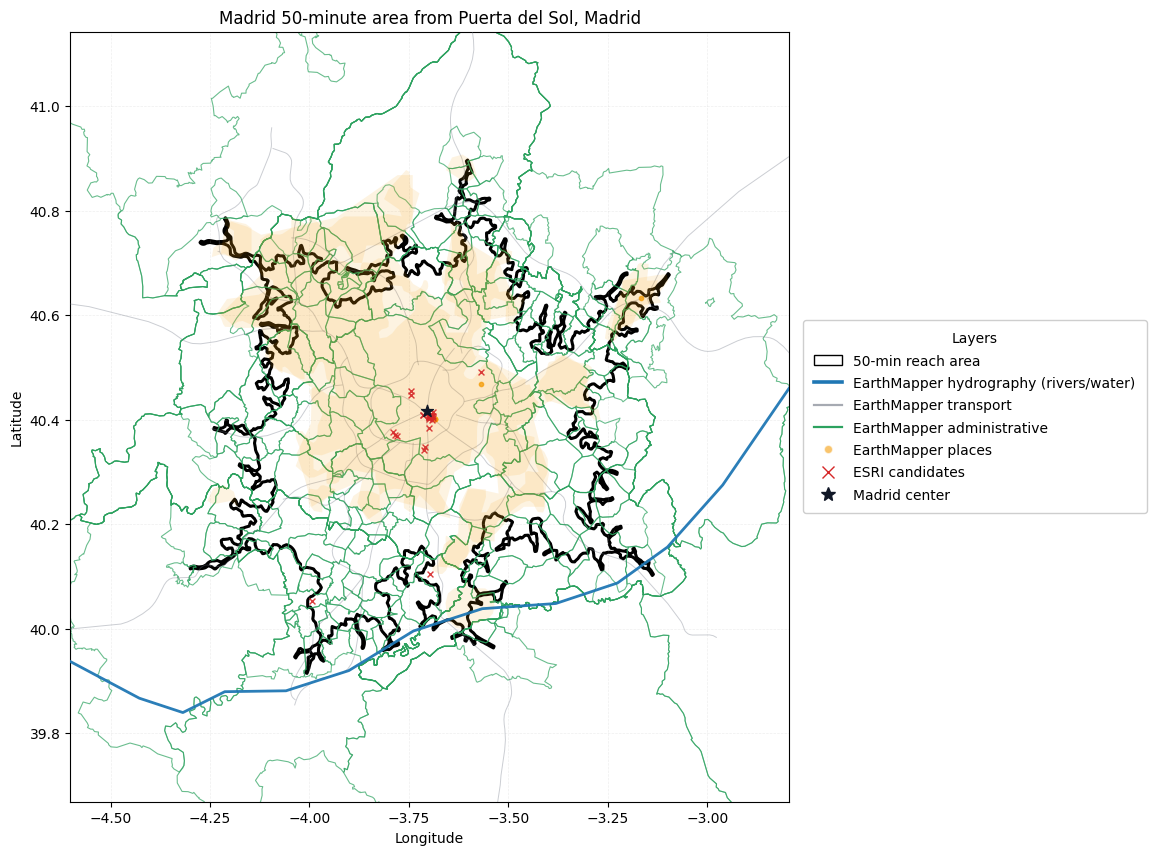

In [9]:
# Improved map visualization (rivers emphasized + external legend)
plot_rows = [
    {"source": "context", "category": "isochrone", "geometry": iso_poly},
    {"source": "context", "category": "center", "geometry": center_point},
]

for cat, data in artifacts.items():
    # Pull extra hydrography to improve river density in visualization.
    earth_df = data.get("earthmapper", pd.DataFrame())
    if cat == "hydrography":
        try:
            extra_hydro = fetch_earthmapper_in_area(iso_poly, category="hydrography", limit=2000)
            if not extra_hydro.empty:
                earth_df = pd.concat([earth_df, extra_hydro], ignore_index=True)
                if "id" in earth_df.columns:
                    earth_df = earth_df.drop_duplicates(subset=["id"], keep="first")
                else:
                    earth_df = earth_df.drop_duplicates(subset=["name", "subcategory"], keep="first")
        except Exception as exc:
            print(f"Hydrography enrichment skipped: {exc}")

    for _, r in earth_df.iterrows():
        g = r.get("geometry")
        if g is not None and not g.is_empty:
            plot_rows.append({
                "source": "earthmapper",
                "category": cat,
                "name": r.get("name"),
                "geometry": g,
            })

    for _, r in data.get("esri", pd.DataFrame()).iterrows():
        g = r.get("geometry")
        if g is not None and not g.is_empty:
            plot_rows.append({
                "source": "esri",
                "category": cat,
                "name": r.get("name"),
                "geometry": g,
            })

if plot_rows:
    try:
        import matplotlib.pyplot as plt
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch

        gdf_plot = gpd.GeoDataFrame(plot_rows, geometry="geometry", crs="EPSG:4326")

        fig, ax = plt.subplots(figsize=(12, 10))

        # Base travel-time area outline
        ctx_iso = gdf_plot[(gdf_plot["source"] == "context") & (gdf_plot["category"] == "isochrone")]
        if not ctx_iso.empty:
            ctx_iso.boundary.plot(ax=ax, color="black", linewidth=2.2, zorder=1)

        # EarthMapper layers (draw in semantic order)
        em = gdf_plot[gdf_plot["source"] == "earthmapper"]
        if not em.empty:
            em_admin = em[em["category"] == "administrative"]
            if not em_admin.empty:
                em_admin.boundary.plot(ax=ax, color="#2ca25f", linewidth=0.8, alpha=0.7, zorder=2)

            em_transport = em[em["category"] == "transport"]
            if not em_transport.empty:
                em_transport.plot(ax=ax, color="#6b7280", linewidth=0.7, alpha=0.35, zorder=3)

            em_places = em[em["category"] == "places"]
            if not em_places.empty:
                place_polys = em_places[em_places.geometry.geom_type.isin(["Polygon", "MultiPolygon"])]
                place_lines = em_places[em_places.geometry.geom_type.isin(["LineString", "MultiLineString"])]
                place_points = em_places[em_places.geometry.geom_type.isin(["Point", "MultiPoint"])]

                if not place_polys.empty:
                    place_polys.plot(ax=ax, color="#f59e0b", alpha=0.12, linewidth=0.0, zorder=4)
                if not place_lines.empty:
                    place_lines.plot(ax=ax, color="#f59e0b", alpha=0.28, linewidth=0.7, zorder=4)
                if not place_points.empty:
                    place_points.plot(ax=ax, color="#f59e0b", markersize=9, alpha=0.5, zorder=5)

            # Draw hydrography last so rivers stay visible on top.
            em_hydro = em[em["category"] == "hydrography"]
            if not em_hydro.empty:
                em_hydro.plot(ax=ax, color="#1f77b4", linewidth=2.0, alpha=0.95, zorder=6)

        # ESRI points
        esri = gdf_plot[gdf_plot["source"] == "esri"]
        if not esri.empty:
            esri.plot(ax=ax, color="#d62728", markersize=18, marker="x", linewidth=1.0, alpha=0.9, zorder=7)

        # Center point
        ctx_center = gdf_plot[(gdf_plot["source"] == "context") & (gdf_plot["category"] == "center")]
        if not ctx_center.empty:
            ctx_center.plot(ax=ax, color="#111827", markersize=80, marker="*", zorder=8)

        # Zoom to the travel-time area to reveal river detail.
        minx, miny, maxx, maxy = iso_poly.bounds
        padx = max((maxx - minx) * 0.25, 0.05)
        pady = max((maxy - miny) * 0.25, 0.05)
        ax.set_xlim(minx - padx, maxx + padx)
        ax.set_ylim(miny - pady, maxy + pady)

        # Styled legend outside map area
        legend_handles = [
            Patch(facecolor="none", edgecolor="black", label="50-min reach area"),
            Line2D([0], [0], color="#1f77b4", lw=2.6, label="EarthMapper hydrography (rivers/water)"),
            Line2D([0], [0], color="#6b7280", lw=1.6, alpha=0.6, label="EarthMapper transport"),
            Line2D([0], [0], color="#2ca25f", lw=1.6, label="EarthMapper administrative"),
            Line2D([0], [0], marker="o", color="w", markerfacecolor="#f59e0b", markersize=6, alpha=0.6, label="EarthMapper places"),
            Line2D([0], [0], marker="x", color="#d62728", markersize=8, lw=0, label="ESRI candidates"),
            Line2D([0], [0], marker="*", color="#111827", markersize=10, lw=0, label="Madrid center"),
        ]

        ax.legend(
            handles=legend_handles,
            loc="center left",
            bbox_to_anchor=(1.01, 0.5),
            frameon=True,
            framealpha=0.95,
            title="Layers",
            borderpad=0.8,
            labelspacing=0.6,
        )

        ax.set_title(f"Madrid {TRAVEL_MINUTES}-minute area from {CENTER_QUERY}")
        ax.set_xlabel("Longitude")
        ax.set_ylabel("Latitude")
        ax.grid(alpha=0.2, linestyle="--", linewidth=0.5)
        fig.subplots_adjust(right=0.74)
        plt.show()
    except Exception as exc:
        print(f"Map skipped: {exc}")